# **Random Forest (Кездейсоқ орман)** — бірнеше шешім ағашын құрып, олардың болжамдарын біріктіретін ансамбльдік машиналық оқыту алгоритмі.

Бұл тәсіл модельдің дәлдігін арттырып, шамадан тыс үйренуді (**overfitting**) азайтуға көмектеседі.

Scikit-learn кітапханасындағы **Random Forest Classifier** жіктеу есептерінде кеңінен қолданылады. Себебі ол үлкен деректер жиындарымен жұмыс істей алады және белгілер арасындағы сызықтық емес байланыстарды жақсы анықтайды.

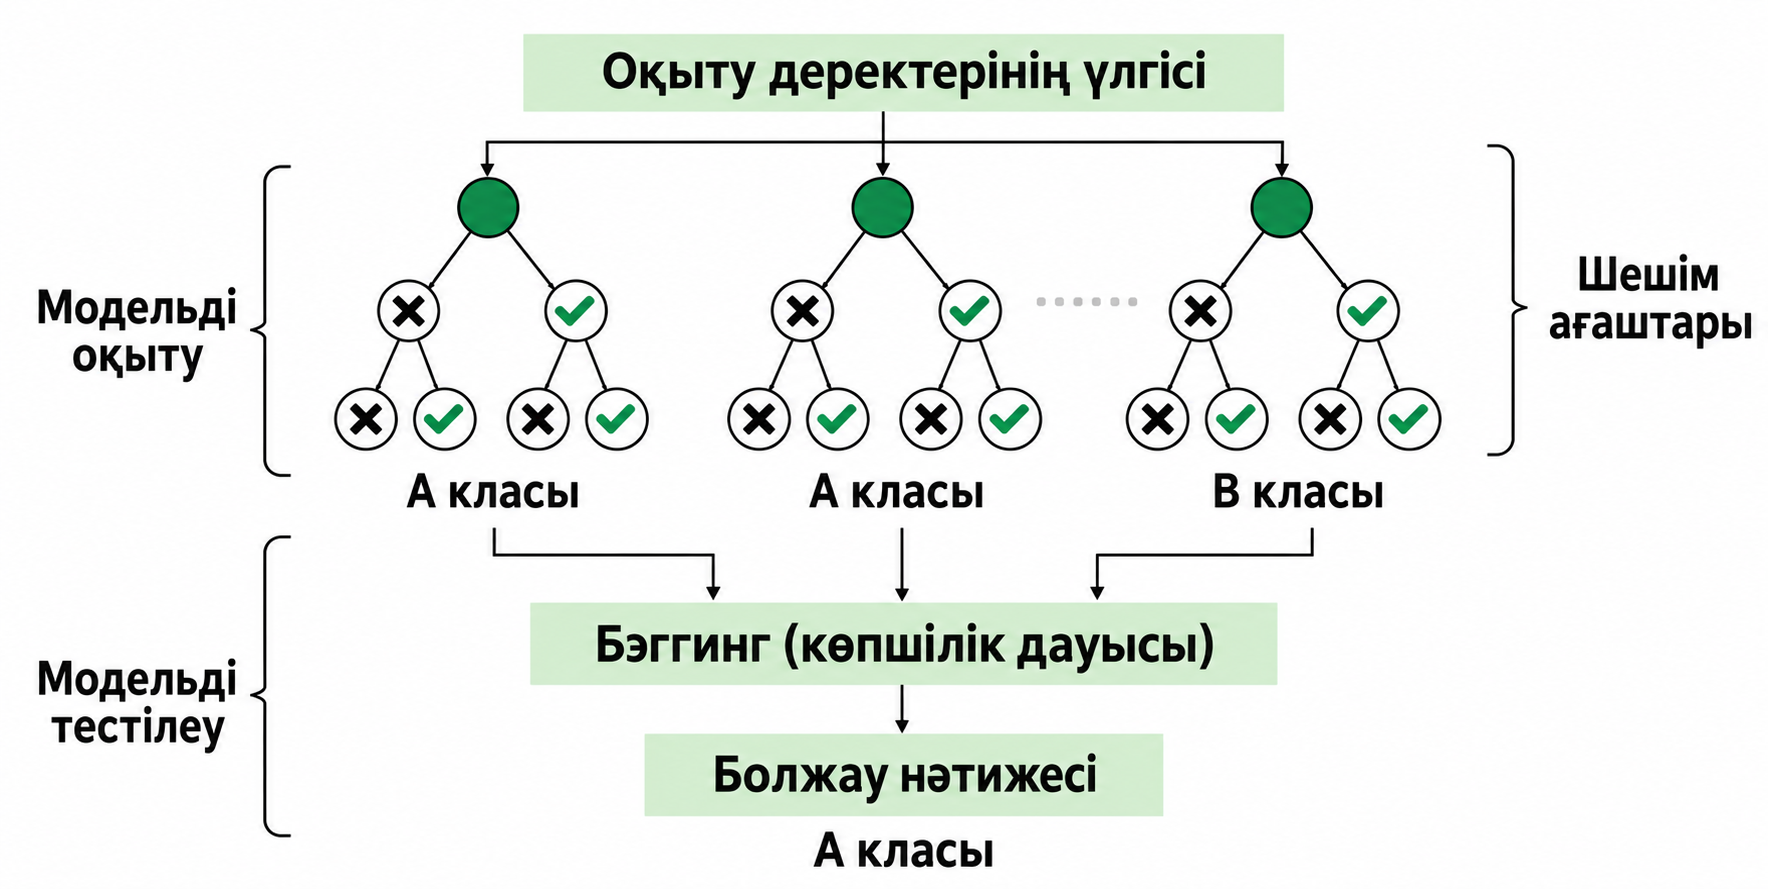

## Random Forest классификаторының жұмыс істеу принципі

1. **Бутстрэп іріктеу (Bootstrap Sampling):** Әрбір шешім ағашын оқыту үшін деректер жиынынан жолдар кездейсоқ және қайтарымды түрде таңдалады. Бір жол бірнеше рет таңдалуы мүмкін.

2. **Белгілерді кездейсоқ таңдау (Random Feature Selection):** Әрбір ағаш барлық белгілерді емес, олардың кездейсоқ таңдалған бөлігін пайдаланады.

3. **Шешім ағаштарын құру:** Әр түйінде кездейсоқ таңдалған белгілердің ішінен деректерді ең жақсы бөлетін белгі анықталады. Бөлу белгіленген тоқтау шартына, мысалы, максималды тереңдікке жеткенше жалғасады.

4. **Болжам жасау:** Әрбір шешім ағашы жеке болжам береді.

5. **Көпшілік дауыс:** Ағаштардың көпшілігі таңдаған класс қорытынды болжам ретінде қабылданады.

## Random Forest классификациясының артықшылықтары

- Үлкен және белгілер саны көп деректер жиындарымен жұмыс істей алады.
- Көптеген шешім ағаштарының болжамдарын біріктіру арқылы бір шешім ағашымен салыстырғанда шамадан тыс үйрену қаупін азайтады.
- Шулы деректерге төзімді және категориялық деректермен жақсы жұмыс істей алады.

## Python тілінде Random Forest классификациясын жүзеге асыру

Python тілінде Random Forest классификаторын құрмас бұрын, оның негізгі гиперпараметрлерін түсініп алайық.

- **`n_estimators`** — ормандағы шешім ағаштарының саны.
- **`max_depth`** — әрбір ағаштың максималды тереңдігі.
- **`max_features`** — әрбір түйінде бөлу үшін қарастырылатын белгілер саны.
- **`criterion`** — бөлудің сапасын бағалайтын функция (`'gini'` немесе `'entropy'`).
- **`min_samples_split`** — түйінді бөлу үшін қажетті объектілердің ең аз саны.
- **`min_samples_leaf`** — соңғы жапырақ түйінде қалуы тиіс объектілердің ең аз саны.
- **`bootstrap`** — ағаштарды құру кезінде бутстрэп іріктеуін қолдану керектігін анықтайды (`True` немесе `False`).

Енді Random Forest параметрлерін түсінгеннен кейін, оны Python тілінде құруды бастай аламыз.

### 1. Қажетті кітапханаларды импорттау

Модельді құру үшін **Pandas**, **Matplotlib**, **Seaborn** және **Scikit-learn (`sklearn`)** кітапханаларын импорттаймыз.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris

### **2. Деректер жиынын жүктеу**

Бұл тапсырмада `Scikit-learn` кітапханасында дайын түрде берілген **Iris деректер жиынын** қолданамыз. Бұл деректер жиынында ирис гүлінің үш түрі және олардың келесі белгілері туралы ақпарат бар:

- тостағанша жапырақшасының ұзындығы (`sepal length`);
- тостағанша жапырақшасының ені (`sepal width`);
- күлте жапырақшасының ұзындығы (`petal length`);
- күлте жапырақшасының ені (`petal width`).

In [2]:
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target

df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


### **3. Деректерді дайындау**

Бұл кезеңде кіріс белгілерін **`X`** және мақсатты айнымалыны **`y`** ретінде бөлеміз.

In [3]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

### **4. Деректер жиынын бөлу**

Модельді деректердің бір бөлігімен оқытып, екінші бөлігімен бағалау үшін деректер жиынын **оқыту** және **тестілеу** бөліктеріне бөлеміз.

- **`X_train`, `y_train`** — модельді оқытуға қолданылатын деректердің 80%-ы.
- **`X_test`, `y_test`** — модельді тестілеуге қолданылатын деректердің 20%-ы.
- **`test_size=0.2`** — деректердің 20%-ы тестілеуге бөлінетінін білдіреді.
- **`random_state=42`** — кодты әр іске қосқанда деректердің бірдей бөлінуін қамтамасыз етеді.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### **5. Белгілерді масштабтау**

Белгілерді масштабтау барлық белгілердің мәндерін шамалас ауқымға келтіреді. Бұл кейбір машиналық оқыту модельдері үшін маңызды.

Алайда **Random Forest** моделі белгілердің масштабына аса сезімтал емес. Сондықтан оны жеке қолданғанда масштабтау міндетті емес. Бірақ бірнеше модельді біріктіріп қолданған кезде белгілерді масштабтау пайдалы әрі дұрыс тәжірибе болып саналады.

In [5]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### **6. Random Forest классификаторын құру**

**Random Forest Classifier** моделін құрамыз, оны оқыту деректерімен үйретеміз және тест деректері бойынша болжам жасаймыз.

- **`RandomForestClassifier(n_estimators=100, random_state=42)`** — 100 шешім ағашынан тұратын Random Forest моделін құрады. 100 ағаш дәлдік пен оқыту уақыты арасындағы қолайлы теңгерімді қамтамасыз етеді.
- **`classifier.fit(X_train, y_train)`** — модельді оқыту деректерімен үйретеді.
- **`classifier.predict(X_test)`** — тест деректері бойынша болжам жасайды.
- **`random_state=42`** — кодты әр іске қосқанда бірдей нәтижелердің алынуын қамтамасыз етеді.

In [6]:
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

### **7. Модельді бағалау**

Модельдің жұмыс нәтижесін **дәлдік көрсеткіші (`accuracy score`)** және **қателер матрицасы (`confusion matrix`)** арқылы бағалаймыз.

Accuracy: 100.00%


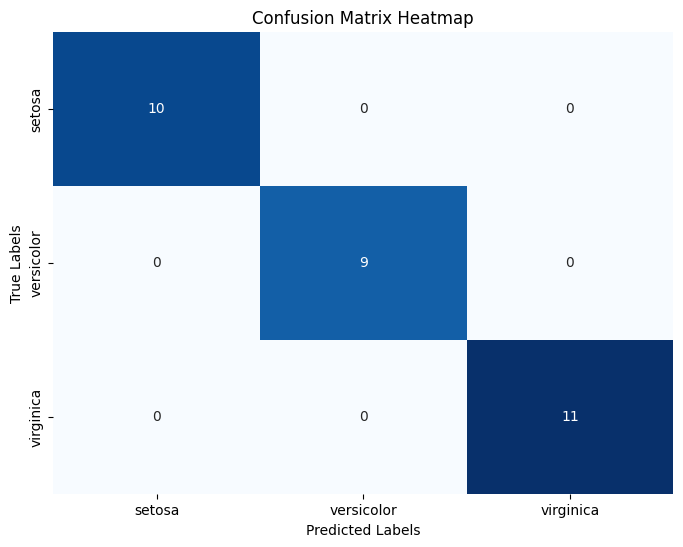

In [7]:
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False,
            xticklabels=iris.target_names, yticklabels=iris.target_names)

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

### **8. Белгілердің маңыздылығы**

**Random Forest** классификаторы болжам жасау кезінде қай белгілердің маңызды рөл атқарғанын анықтауға мүмкіндік береді. Белгілердің маңыздылығын график түрінде көрсетуге болады.

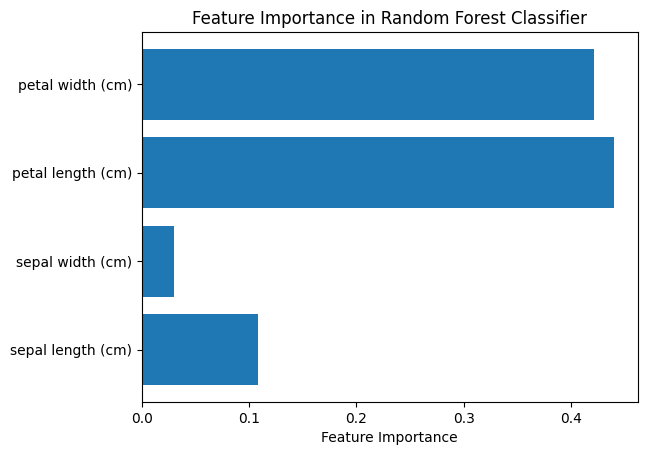

In [8]:
feature_importances = classifier.feature_importances_

plt.barh(iris.feature_names, feature_importances)
plt.xlabel('Feature Importance')
plt.title('Feature Importance in Random Forest Classifier')
plt.show()

Графиктен **күлте жапырақшасының ені (`petal width`)** ең маңызды белгі екенін көруге болады. Одан кейін маңыздылығы жағынан **күлте жапырақшасының ұзындығы (`petal length`)** орналасқан.

Ал **тостағанша жапырақшасының ені (`sepal width`)** мен **ұзындығының (`sepal length`)** модель болжамына әсері төменірек.

Бұл классификатор ирис гүлінің түрін болжау кезінде көбінесе **күлте жапырақшасының өлшемдеріне** сүйенетінін көрсетеді.